In [18]:
# -----------------------------
# Setup/Iports
# -----------------------------
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
from sklearn.metrics import confusion_matrix, classification_report
import os
import random
from PIL import Image, ImageEnhance
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from sklearn.utils import shuffle
import tensorflow as tf
from tensorflow.keras.layers import (Input, Flatten, Dropout, Dense, BatchNormalization, GlobalAveragePooling2D, Multiply, Reshape, Conv2D, Lambda)
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import VGG16
import gradio as gr


warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 600,
    'savefig.format': 'pdf',
    'savefig.bbox': 'tight',
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'DejaVu Serif'],
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 16,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 11,
    'legend.frameon': True,
    'legend.framealpha': 1.0,
    'legend.edgecolor': '#000000',
    'legend.fancybox': False,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.spines.left': True,
    'axes.spines.bottom': True,
    'axes.linewidth': 1.5,
    'axes.grid': False,
    'lines.linewidth': 2.5,
    'lines.markersize': 8,
    'patch.linewidth': 1.5,
    'patch.edgecolor': '#000000',
    'text.color': '#000000',
    'axes.labelcolor': '#000000',
    'axes.edgecolor': '#000000',
    'xtick.color': '#000000',
    'ytick.color': '#000000',
    'xtick.major.width': 1.5,
    'ytick.major.width': 1.5,
    'xtick.major.size': 5,
    'ytick.major.size': 5,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
})

In [19]:
# -----------------------------
# Dataset directories
# -----------------------------
train_dir = '/kaggle/input/brain-tumor-mri-dataset/Training'
test_dir = '/kaggle/input/brain-tumor-mri-dataset/Testing'

# Load and shuffle train data
train_paths, train_labels = [], []
for label in os.listdir(train_dir):
    for image in os.listdir(os.path.join(train_dir, label)):
        train_paths.append(os.path.join(train_dir, label, image))
        train_labels.append(label)
train_paths, train_labels = shuffle(train_paths, train_labels)

# Load test data
test_paths, test_labels = [], []
for label in os.listdir(test_dir):
    for image in os.listdir(os.path.join(test_dir, label)):
        test_paths.append(os.path.join(test_dir, label, image))
        test_labels.append(label)

print(f"Training samples: {len(train_paths)}, Test samples: {len(test_paths)}")

Training samples: 5712, Test samples: 1311


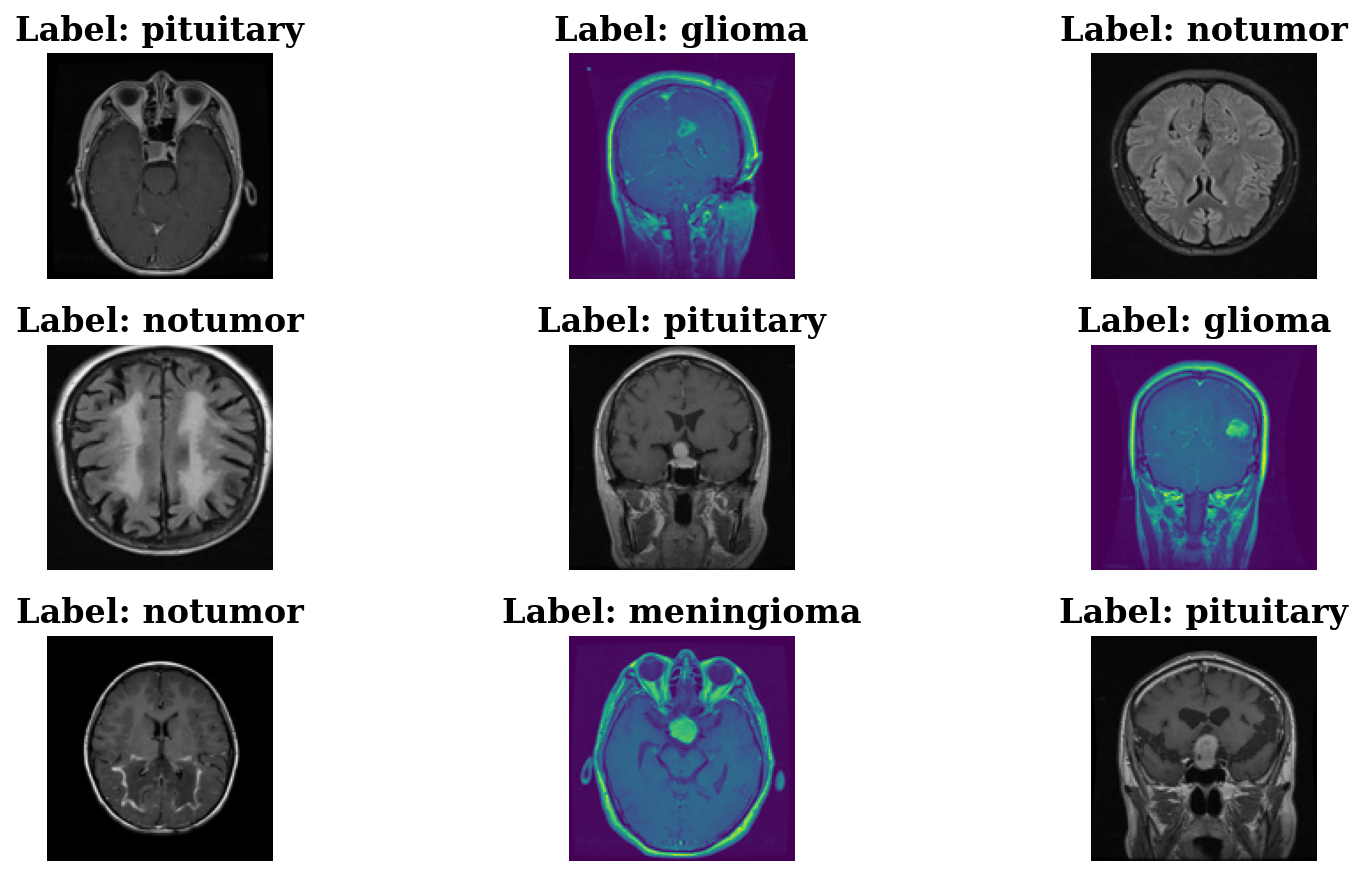

In [20]:
# -----------------------------
# Sample image display
# -----------------------------
sample_indices = random.sample(range(len(train_paths)), 9)
plt.figure(figsize=(12,6))
for i, idx in enumerate(sample_indices):
    im = Image.open(train_paths[idx]).resize((128,128))
    plt.subplot(3,3,i+1)
    plt.imshow(im)
    plt.axis('off')
    plt.title(f"Label: {train_labels[idx]}")
plt.tight_layout()
plt.show()

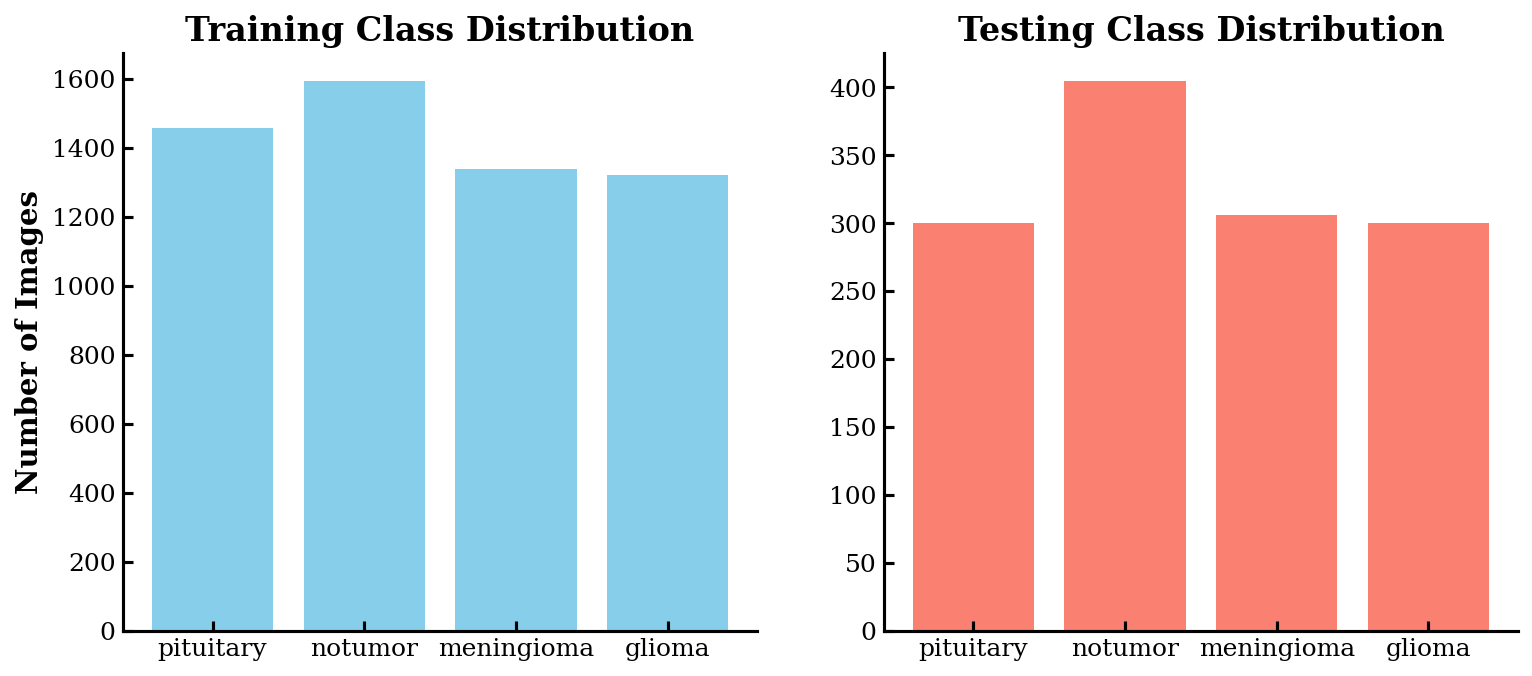

In [21]:
# -----------------------------
# Class distribution plots
# -----------------------------
base_dir = '/kaggle/input/brain-tumor-mri-dataset'
def get_class_counts(split):
    split_dir = os.path.join(base_dir, split)
    counts = {}
    for cls in os.listdir(split_dir):
        cls_path = os.path.join(split_dir, cls)
        if os.path.isdir(cls_path):
            counts[cls] = len(os.listdir(cls_path))
    return counts
train_counts = get_class_counts('Training')
test_counts = get_class_counts('Testing')
fig, axes = plt.subplots(1,2,figsize=(12,5))
axes[0].bar(train_counts.keys(), train_counts.values(), color='skyblue')
axes[0].set_title('Training Class Distribution')
axes[0].set_ylabel('Number of Images')
axes[1].bar(test_counts.keys(), test_counts.values(), color='salmon')
axes[1].set_title('Testing Class Distribution')
plt.show()

In [22]:
# -----------------------------
# Image augmentation 
# -----------------------------
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMAGE_SIZE = 224
BATCH_SIZE = 32

# Training data generator with augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,          # Random rotation
    width_shift_range=0.2,      # Horizontal shift
    height_shift_range=0.2,     # Vertical shift
    shear_range=0.15,            # Shear
    zoom_range=0.2,             # Zoom
    horizontal_flip=True,       # Horizontal flip
    vertical_flip=True,         # Vertical flip
    brightness_range=[0.7, 1.3],# Brightness
    fill_mode='nearest'         # Fill missing pixels
)

# Test / validation generator (only rescale)
test_datagen = ImageDataGenerator(rescale=1./255)

# Encode labels
def encode_label(labels, train_dir):
    unique_labels = sorted(os.listdir(train_dir))
    return np.array([unique_labels.index(l) for l in labels])

# Data generator for model.fit
def datagen(paths, labels, batch_size=BATCH_SIZE, train=True):
    datagen_used = train_datagen if train else test_datagen
    n = len(paths)
    while True:
        for i in range(0, n, batch_size):
            batch_paths = paths[i:i+batch_size]
            batch_labels = labels[i:i+batch_size]

            # Load images
            batch_imgs = np.array([
                np.array(load_img(p, target_size=(IMAGE_SIZE, IMAGE_SIZE)))
                for p in batch_paths
            ])

            # Apply augmentation 
            if train:
                batch_imgs = next(datagen_used.flow(batch_imgs, batch_size=len(batch_imgs), shuffle=False))
            else:
                batch_imgs = batch_imgs / 255.0

            yield batch_imgs, np.array(batch_labels)


In [23]:
# -----------------------------
# CBAM block
# -----------------------------
def cbam_block(inputs, ratio=8):
    channel = GlobalAveragePooling2D()(inputs)
    channel = Reshape((1,1,inputs.shape[-1]))(channel)
    channel = Dense(inputs.shape[-1]//ratio, activation='relu')(channel)
    channel = Dense(inputs.shape[-1], activation='sigmoid')(channel)
    channel_out = Multiply()([inputs, channel])

    spatial = Lambda(lambda x: tf.reduce_mean(x, axis=-1, keepdims=True))(channel_out)
    spatial = Conv2D(1, kernel_size=7, padding='same', activation='sigmoid')(spatial)
    out = Multiply()([channel_out, spatial])
    return out

In [24]:
# -----------------------------
# Model with VGG16 + CBAM
# -----------------------------
inputs = Input(shape=(IMAGE_SIZE, IMAGE_SIZE,3))
base_model = VGG16(input_shape=(IMAGE_SIZE, IMAGE_SIZE,3), include_top=False, weights='imagenet')
for layer in base_model.layers[:-8]:
    layer.trainable=False
x = base_model(inputs, training=False)
x = cbam_block(x)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.55)(x)
x = Dense(256, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
x = BatchNormalization()(x)
x = Dropout(0.35)(x)
outputs = Dense(len(os.listdir(train_dir)), activation='softmax')(x)
model = Model(inputs, outputs)
model.compile(optimizer=Adam(0.0001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ input_layer_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ vgg16[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_2 (Reshape) │ (None, 1, 1, 512) │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 1, 1, 64)  │     32,832 │ reshape_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 1, 1, 512) │     33,280 │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_4          │ (None, 7, 7, 512) │          0 │ vgg16[0][0],      │
│ (Multiply)          │                   │            │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_2 (Lambda)   │ (None, 7, 7, 1)   │          0 │ multiply_4[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 7, 7, 1)   │         50 │ lambda_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_5          │ (None, 7, 7, 512) │          0 │ multiply_4[0][0], │
│ (Multiply)          │                   │            │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ multiply_5[0][0]  │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 512)       │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 256)       │    131,328 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_10[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 256)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 4)         │      1,028 │ dropout_5[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,914,230 (56.89 MB)

 Trainable params: 13,178,230 (50.27 MB)

 Non-trainable params: 1,736,000 (6.62 MB)

In [25]:
# -----------------------------
# Training
# -----------------------------
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

batch_size = 32
train_steps = len(train_paths)//batch_size
val_steps = len(test_paths)//batch_size
epochs = 25

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7)

# Encode labels for training and testing
train_labels_encoded = encode_label(train_labels, train_dir)
test_labels_encoded = encode_label(test_labels, train_dir)

history = model.fit(
    datagen(train_paths, train_labels_encoded, batch_size=batch_size, train=True),
    epochs=epochs,
    steps_per_epoch=train_steps,
    validation_data=datagen(test_paths, test_labels_encoded, batch_size=batch_size, train=False),
    validation_steps=val_steps,
    callbacks=[early_stop, reduce_lr]
)


Epoch 1/25
178/178 ━━━━━━━━━━━━━━━━━━━━ 94s 494ms/step - accuracy: 0.4735 - loss: 1.3644 - val_accuracy: 0.7188 - val_loss: 0.7064 - learning_rate: 1.0000e-04
Epoch 2/25
178/178 ━━━━━━━━━━━━━━━━━━━━ 90s 490ms/step - accuracy: 0.8033 - loss: 0.5738 - val_accuracy: 0.8570 - val_loss: 0.4039 - learning_rate: 1.0000e-04
Epoch 3/25
178/178 ━━━━━━━━━━━━━━━━━━━━ 88s 494ms/step - accuracy: 0.8831 - loss: 0.3885 - val_accuracy: 0.8812 - val_loss: 0.4061 - learning_rate: 1.0000e-04
Epoch 4/25
178/178 ━━━━━━━━━━━━━━━━━━━━ 85s 478ms/step - accuracy: 0.8994 - loss: 0.3111 - val_accuracy: 0.9429 - val_loss: 0.2083 - learning_rate: 1.0000e-04
Epoch 5/25
178/178 ━━━━━━━━━━━━━━━━━━━━ 81s 454ms/step - accuracy: 0.9194 - loss: 0.2614 - val_accuracy: 0.9070 - val_loss: 0.3128 - learning_rate: 1.0000e-04
Epoch 6/25
178/178 ━━━━━━━━━━━━━━━━━━━━ 80s 452ms/step - accuracy: 0.9292 - loss: 0.2434 - val_accuracy: 0.9257 - val_loss: 0.2740 - learning_rate: 1.0000e-04
Epoch 7/25
178/178 ━━━━━━━━━━━━━━━━━━━━ 81s 45

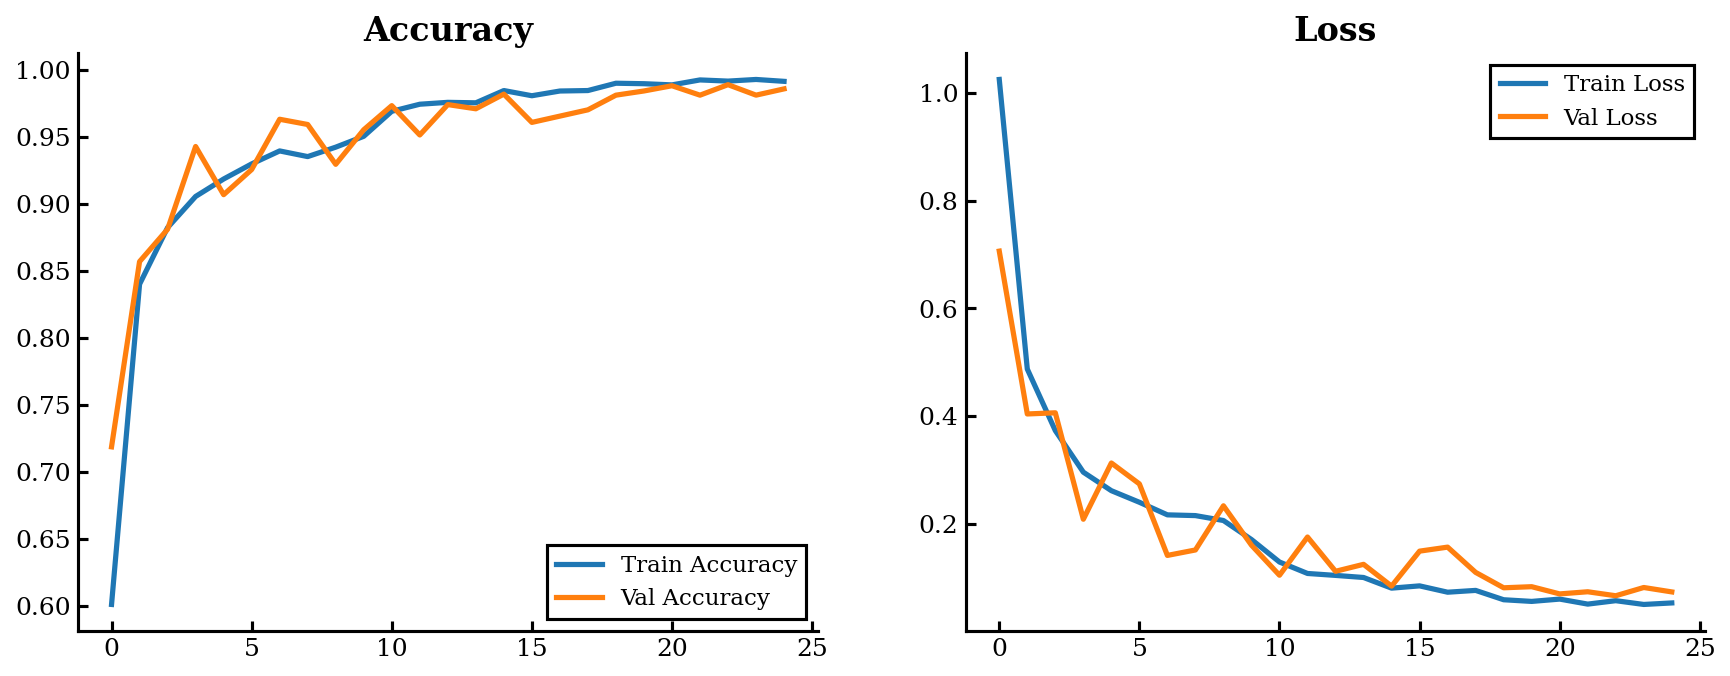

In [26]:
# -----------------------------
# Evaluation plots 
# -----------------------------
plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy')
plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss')
plt.legend()
plt.show()

41/41 ━━━━━━━━━━━━━━━━━━━━ 9s 205ms/step
Classification Report:

              precision    recall  f1-score   support

      glioma       0.99      0.98      0.98       300
  meningioma       0.98      0.98      0.98       306
     notumor       1.00      1.00      1.00       405
   pituitary       0.98      0.99      0.99       300

    accuracy                           0.99      1311
   macro avg       0.99      0.99      0.99      1311
weighted avg       0.99      0.99      0.99      1311



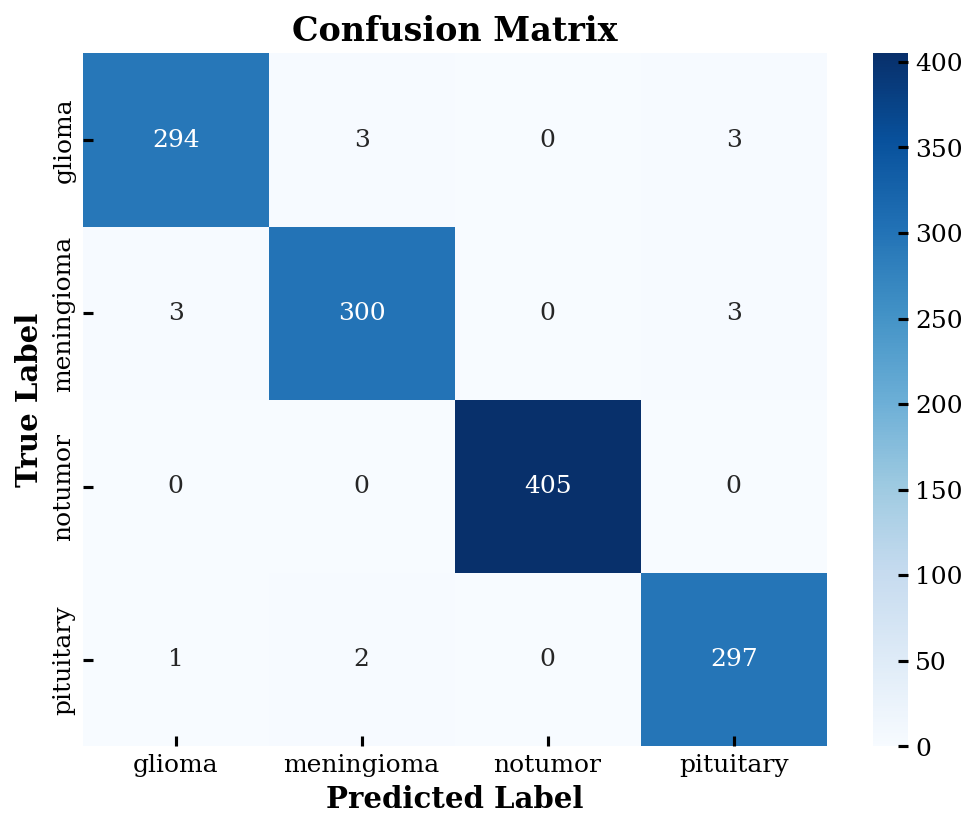

In [27]:
# -----------------------------
# Confusion Matrix & Classification Report
# -----------------------------
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Define class labels (same order as training)
class_labels = sorted(os.listdir(train_dir))

# Get true labels
y_true = test_labels_encoded[:len(test_paths)]

# Generate predictions
y_pred_probs = model.predict(
    datagen(test_paths, test_labels_encoded, batch_size=32, train=False),
    steps=len(test_paths)//32 + 1
)

# Convert probabilities to class indices
y_pred = np.argmax(y_pred_probs, axis=1)[:len(y_true)]

# Print classification report
print("Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_labels))

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot confusion matrix
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels,
            yticklabels=class_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()


In [30]:
# -----------------------------
# Premium Medical-Themed Gradio UI
# -----------------------------
import gradio as gr

class_labels = ['pituitary', 'glioma', 'notumor', 'meningioma']

def predict_tumor(image):
    img = image.resize((IMAGE_SIZE, IMAGE_SIZE))
    img_array = img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    preds = model.predict(img_array)[0]
    pred_idx = np.argmax(preds)

    label = class_labels[pred_idx]
    confidence = preds[pred_idx] * 100

    if label == "notumor":
        status = "NEGATIVE"
        color = "#00E676"
    else:
        status = "POSITIVE"
        color = "#FF1744"

    # Probability plot
    fig, ax = plt.subplots(figsize=(6,4))
    ax.bar(class_labels, preds * 100)
    ax.set_ylim(0,100)
    ax.set_ylabel("Confidence (%)")
    ax.set_title("Class Prediction Confidence")
    plt.tight_layout()

    report = f"""
    <div style="
        padding:25px;
        border-radius:18px;
        background: rgba(255,255,255,0.08);
        border: 1px solid rgba(255,255,255,0.15);
        backdrop-filter: blur(12px);
        box-shadow: 0px 10px 30px rgba(0,0,0,0.4);
        text-align:center;
        font-size:20px;
        font-weight:700;
        color:white;
    ">
        <span style='color:{color}; font-size:26px;'>{status}</span><br>
        Diagnosis: <b>{label.upper()}</b><br>
        Confidence: <b>{confidence:.2f}%</b>
    </div>
    """

    return report, confidence, fig


with gr.Blocks(css="""
body {
    margin: 0;
    background: radial-gradient(circle at top right, #1e3c72, #000000);
    font-family: 'Segoe UI', sans-serif;
}

/* Main container */
.gradio-container {
    max-width: 1100px !important;
    margin: auto !important;
    padding: 30px !important;
}

/* Buttons */
#analyze-btn {
    background: linear-gradient(90deg, #00c6ff, #0072ff) !important;
    border: none !important;
    color: white !important;
    font-size: 18px !important;
    font-weight: bold !important;
    border-radius: 14px !important;
    padding: 15px !important;
    transition: 0.3s ease-in-out;
}
#analyze-btn:hover {
    transform: scale(1.02);
    box-shadow: 0px 0px 25px rgba(0,198,255,0.8);
}

/* Image box */
.image-container img {
    border-radius: 20px !important;
    border: 2px solid rgba(255,255,255,0.1) !important;
    box-shadow: 0px 0px 25px rgba(255,255,255,0.05) !important;
}

/* Slider */
input[type=range] {
    accent-color: #00c6ff;
}
""") as demo:

    gr.Markdown("""
    <div style='text-align:center; color:white;'>
        <h1 style='font-size:42px;'>🧠 NeuroVision AI</h1>
        <p style='opacity:0.8; font-size:18px;'>Advanced Brain MRI Tumor Detection System</p>
    </div>
    """)

    with gr.Row():
        with gr.Column(scale=1):
            img_input = gr.Image(
                type="pil",
                label="📤 Upload MRI Scan",
                height=350
            )

        with gr.Column(scale=1):
            diagnosis_output = gr.HTML()
            confidence_output = gr.Slider(
                0, 100, step=0.1,
                interactive=False,
                label="Prediction Confidence (%)"
            )

    prob_plot = gr.Plot(label="Model Confidence Breakdown")

    analyze_button = gr.Button("🚀 Run Diagnostic Scan", elem_id="analyze-btn")

    analyze_button.click(
        predict_tumor,
        inputs=img_input,
        outputs=[diagnosis_output, confidence_output, prob_plot]
    )

demo.launch()


* Running on local URL:  http://127.0.0.1:7863
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

* Running on public URL: https://a1ef537edb73f69e21.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
